# TL2 Análisis de componentes principales (PCA) #

## 1. Introducción

Objetivo: aplicar PCA para reducir la dimensión de los datos; imágenes principalmente

PCA con scikit-learn:
- El método directo (y eficiente) para calcular PCA se basa en hallar la SVD "completa" de la matriz de datos
- La implementación de PCA en scikit-learn emplea un método aleatorizado, más eficiente que el directo

Aplicación a imágenes:
- Usaremos datasets muy populares: MNIST, Fashion-MNIST y CIFAR-10
- La dimensión de los datos en el caso de imágenes suele ser muy grande, lo que dificulta el aprendizaje de clasificadores
- Una aproximación convencional para facilitar el aprendizaje consiste en reducir previamente la dimensión de los datos
- Estudiaremos el error de reconstrucción en función de la dimensión reducida K
- Interpretaremos las componentes principales como imágenes base (eigenimages)
- Reconstruiremos imágenes y las compararemos con sus originales
- Estudiaremos la precisión de regresión logística en función deK
- Aunque trabajemos con imágenes, se puede proceder de forma parecida con otro tipo de datos (de alta dimensión)


## 2 PCA con scikit-learn

Método directo para aplicar PCA: a partir de la SVD "completa" de la matriz de datos

Ejemplo: datos de dimensiones que queremos reducir a dimensión N = 4 D = 2 K = 1

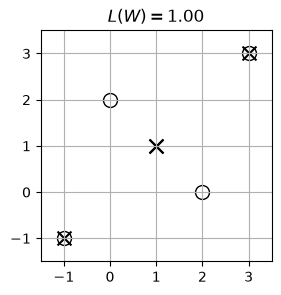

In [6]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([ [-1,-1], [0, 2], [2, 0], [3, 3] ]) 
N = len(X)
K = 1
_,_,Vt = np.linalg.svd(X - X.mean(0))
W = Vt[:K, :].T
Z = X @ W
hX = Z @ W.T
L = np.square(X - hX).sum(axis=1).mean()

fig, ax = plt.subplots(figsize=(3, 3))
ax.set_aspect("equal")
plt.axis([-1.5, 3.5,-1.5, 3.5])

plt.grid(True) 
ax.set_title(f'$L(W)={L:.2f}$')
plt.scatter(*X.T, facecolor='white', edgecolor='k', s=100)
plt.scatter(*hX.T, facecolor='black', s=100, marker='x')

PCA con scikit-learn: emplea un método aleatorizado para matrices grandes, más eficiente que el directo
API: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

Parámetros: n_components, svd_solver, random_state , etc.

Atributos: components_, singular_values_, mean_, n_components , etc.

Métodos: fit(X) , transform(X) , fit_transform(X), inverse_transform(X) , etc.

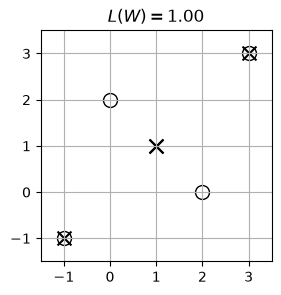

In [7]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA

X = np.array([ [-1,-1], [0, 2], [2, 0], [3, 3] ]) 
N = len(X)
K = 1 
pca = PCA(n_components=K).fit(X - X.mean(0)) 
Z = pca.transform(X)
hX = pca.inverse_transform(Z) 
L = np.square(X - hX).sum(axis=1).mean()


fig, ax = plt.subplots(figsize=(3, 3)) 
ax.set_aspect("equal")
plt.axis([-1.5, 3.5,-1.5, 3.5]) 
plt.grid(True) 
ax.set_title(f'$L(W)={L:.2f}$')
plt.scatter(*X.T, facecolor='white', edgecolor='k', s=100)
plt.scatter(*hX.T, facecolor='black', s=100, marker='x')

## 3. MNIST ##

Modified NIST (MNIST): dataset de 70 000 28 × 28 imágenes en gris de dígitos manuscritos

Muy popular: desde su introducción en los 90, MNIST ha sido muy usado para comparar técnicas de ML

Partición estándar: 60 000 10 000

primeras muestras para training y restantes para test

In [8]:
import numpy as np
import datasets

ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
print(ds)
train0 = ds['train'][0]
train0['image'].shape, train0['image'].dtype, train0['label']

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


((28, 28), dtype('uint8'), np.int64(5))

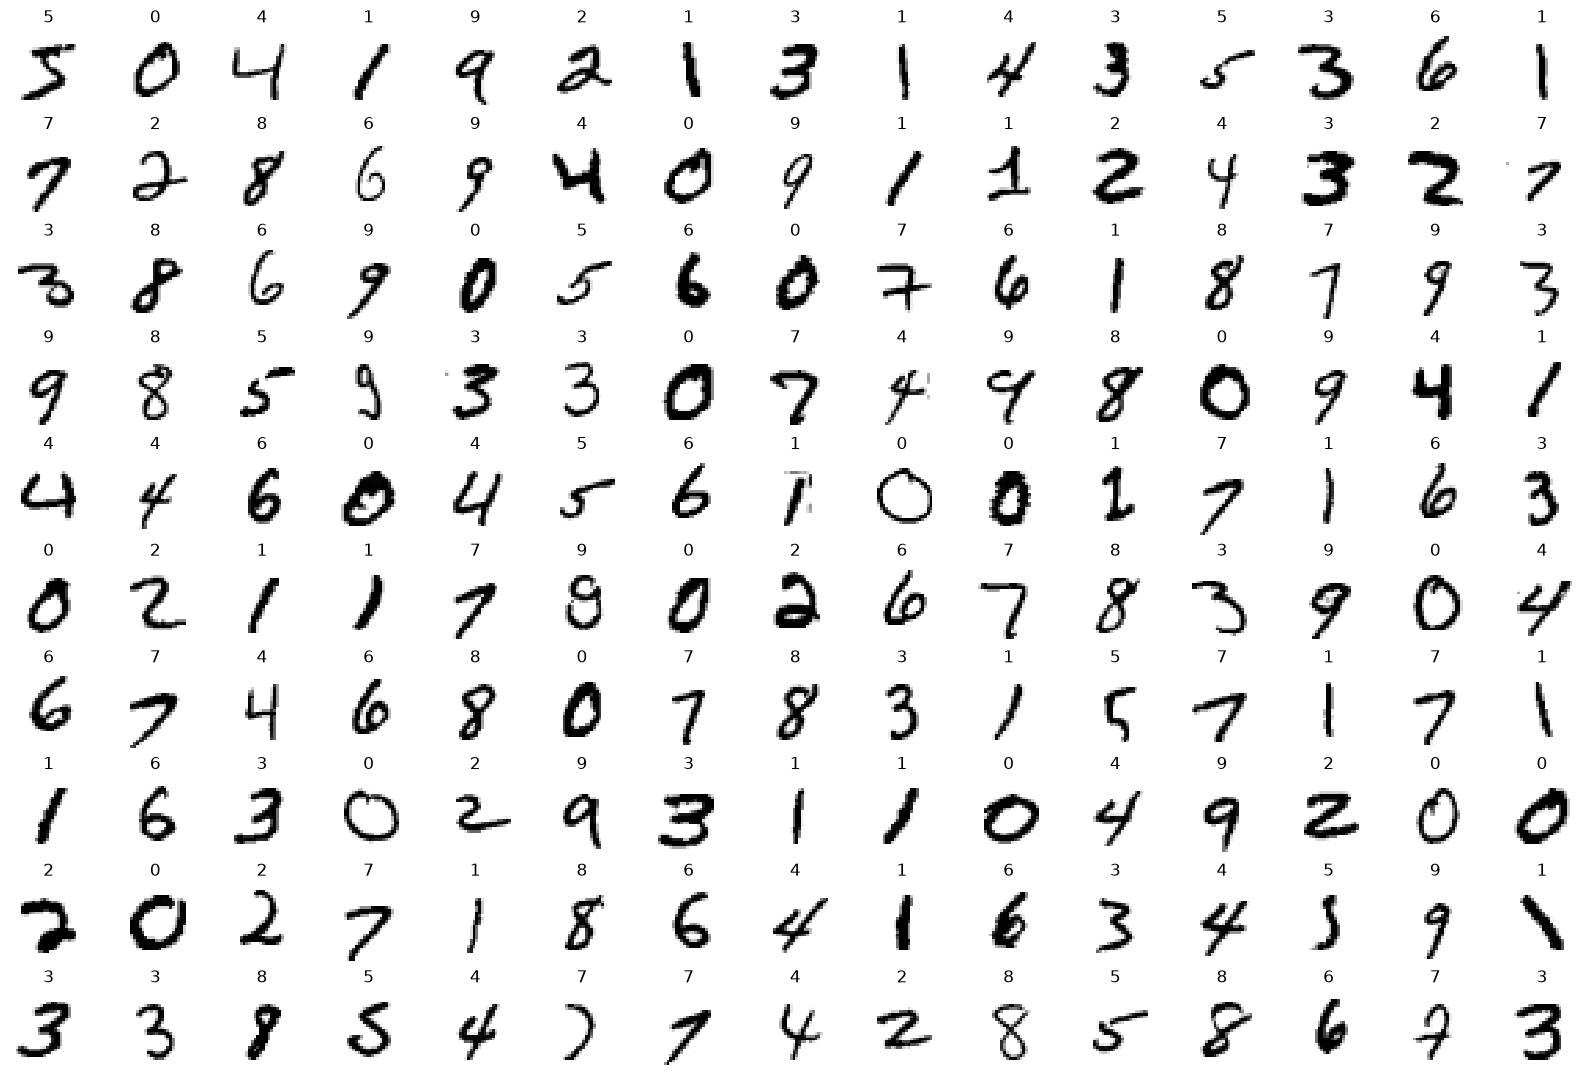

In [9]:
import matplotlib.pyplot as plt
nrows = 10
ncols = 15
N = nrows * ncols

_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 16*nrows/ncols), constrained_layout=True)

for ax, x, y in zip(axs.flat, ds['train'][:N]['image'], ds['train'][:N]['label']):
    ax.set_axis_off()
    ax.imshow(x, cmap=plt.cm.gray_r, interpolation="none")
    ax.set_title(y)

## 4 PCA aplicado a MNIST

Error de reconstrucción: estudio en función de K

In [10]:
import numpy as np 
import datasets
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")

X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)

X_train, X_test, y_train, y_test

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(60000, 784), dtype=float32),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 784), dtype=float32),
 array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8),
 array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8))

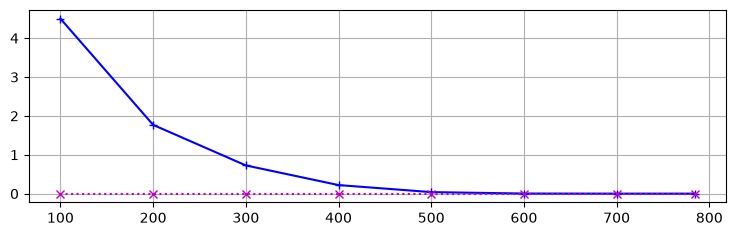

In [11]:
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA
max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])
L_train = np.empty_like(Ks, dtype=float); L_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
    Z_train_K = Z_train.copy(); Z_train_K[:, K:] = 0.0 
    hX_train = pca.inverse_transform(Z_train_K)
    L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()

Z_test_K = Z_test.copy()
Z_test_K[:, K:] = 0.0
hX_test = pca.inverse_transform(Z_test_K)
L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()
plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m');

Eigendigits y reconstrucción: con K = 400

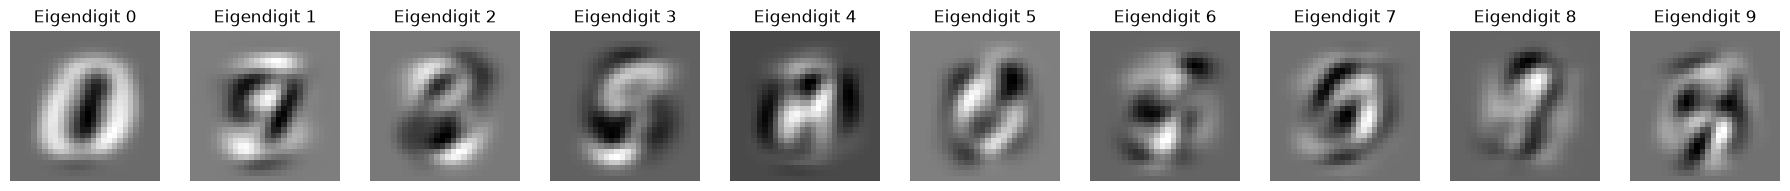

In [12]:
K = 400 
pca = PCA(n_components=K).fit(X_train)
nrows, ncols = 1, 10
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)

for i in range(min(K, nrows * ncols)):
    ax = axs.flat[i]; ax.set_axis_off() 
    ax.set_title(f"Eigendigit {i}")
    ax.imshow(pca.components_[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")

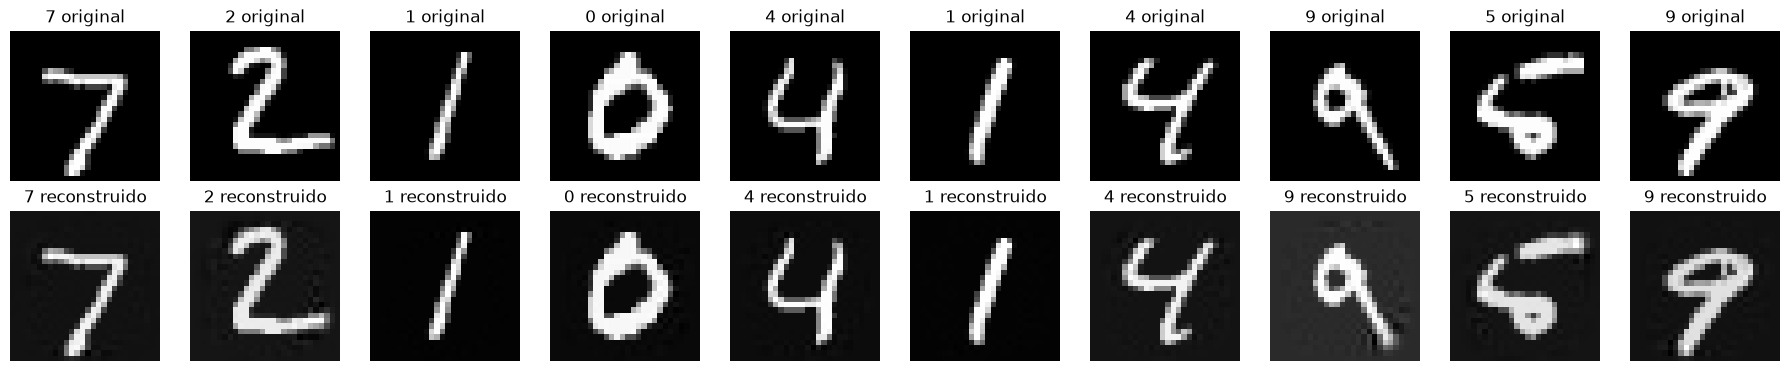

In [13]:
ncols = 10 
Z_test = pca.transform(X_test[:ncols]) 
hX_test = pca.inverse_transform(Z_test)
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)

for i in range(ncols):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} original")
    ax.imshow(X_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} reconstruido")
    ax.imshow(hX_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")

Precisión de regresión logística: estudio en función de K

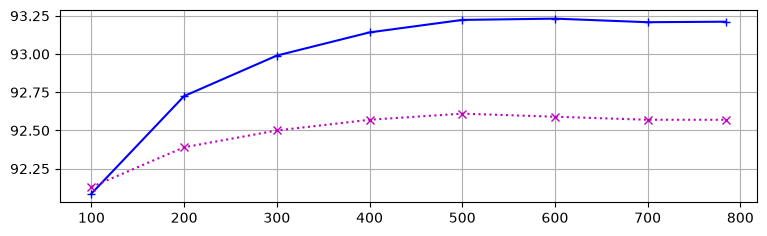

In [14]:
from sklearn.linear_model import LogisticRegression
max_K = np.min(X_train.shape) 
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 300, 400, 500, 600, 700, max_K])
acc_train = np.empty_like(Ks, dtype=float); acc_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
    clf = LogisticRegression(C=0.1, max_iter=200).fit(Z_train[:, :K], y_train)
    acc_train[i] = clf.score(Z_train[:, :K], y_train)
    acc_test[i] = clf.score(Z_test[:, :K], y_test)
plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m')

In [15]:
for i, K in enumerate(Ks): print(f'{K} {acc_test[i]:.1%}', end=' ')

100 92.1% 200 92.4% 300 92.5% 400 92.6% 500 92.6% 600 92.6% 700 92.6% 784 92.6% 

## 5 Fashion-MNIST
Fashion MNIST: MNIST con prendas de ropa; introducido en 2017 como sustituto del ya agotado MNIST

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


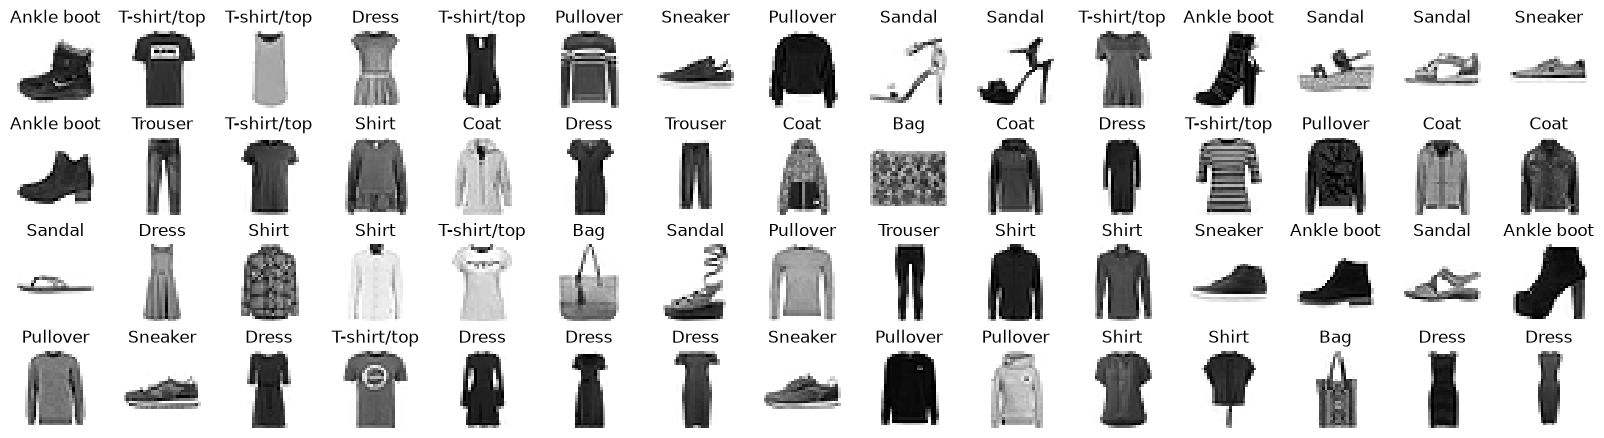

In [16]:
#Fashion MNIST

import numpy as np 
import datasets
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy"); ds
print(ds)

import matplotlib.pyplot as plt; nrows = 4; ncols = 15; N = nrows * ncols
labels = ("T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot")
_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 16*nrows/ncols), constrained_layout=True)

for ax, x, y in zip(axs.flat, ds['train'][:N]['image'], ds['train'][:N]['label']):
    ax.set_axis_off(); ax.imshow(x, cmap=plt.cm.gray_r, interpolation="none"); ax.set_title(labels[y])

## 6 CIFAR-10
CIFAR-10: dataset de 60 000 imágenes 32 × 32 a color de 10 clases; 6000 por clase

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})
(32, 32, 3) uint8 0


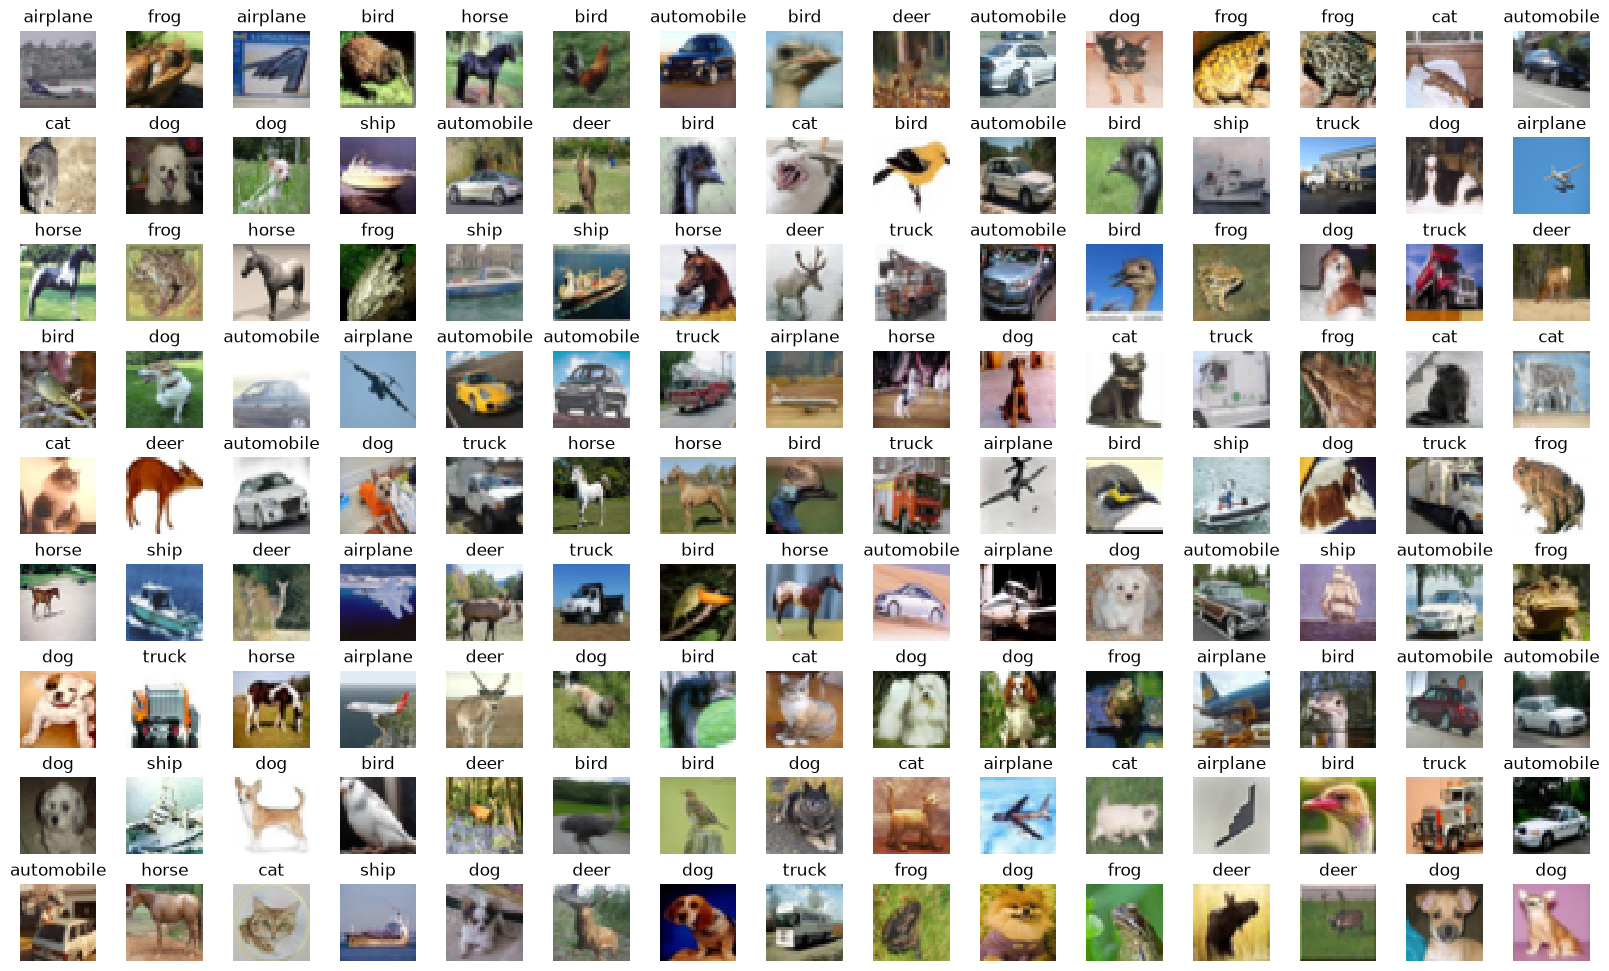

In [17]:
import numpy as np
import datasets
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy") 
print(ds)

train0 = ds['train'][0]
print(train0['img'].shape, train0['img'].dtype, train0['label'])

import matplotlib.pyplot as plt; nrows = 9; ncols = 15; N = nrows * ncols
labels = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
_, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 16*nrows/ncols), constrained_layout=True)
for ax, x, y in zip(axs.flat, ds['train'][:N]['img'], ds['train'][:N]['label']):
    ax.set_axis_off()
    ax.imshow(x, cmap=plt.cm.gray_r, interpolation="none")
    ax.set_title(labels[y])

## 7 Ejercicio

Ejercicio: aplica PCA a Fashion-MNIST y CIFAR-10 siguiendo el ejemplo dado para MNIST

Aplicación a Fashion-MNIST: en comparación con el ejemplo dado para MNIST
- Comprueba que, para obtener un error reconstrucción prácticamente nulo, K ≥ 600(aprox.)
- Representa los diez primeros eigenarticles con K = 600
- Compara las diez primeras imágenes de test con sus reconstrucciones usando K = 600
- Comprueba que regresión logística supera ligeramente el 84% K ≥ 200 de precisión en test con K ≥ 200
  
Aplicación a CIFAR-10: en comparación con el ejemplo dado para MNIST
- Comprueba que, para obtener un error reconstrucción prácticamente nulo, K ≥ 1000(aprox.)
- No trates de representar gráficamente los diez primeros eigenobjects (requiere un PCA por cada canal de color)
- Compara las diez primeras imágenes de test con sus reconstrucciones usando K = 1000
- Comprueba que regresión logística obtiene, aproximadamente, un 41% 

### 7.1 Aplicación a Fashion-MNIST


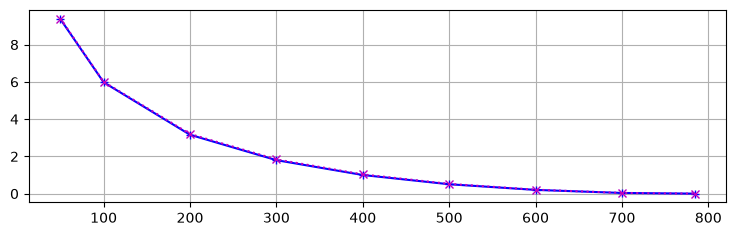

In [19]:
import numpy as np 
import datasets
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA

# Cargar y dividir dataset (formato vector 28*28)
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255
y_train = ds['train'][:]['label'].astype(np.uint8)
y_test = ds['test'][:]['label'].astype(np.uint8)
labels = ("T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot")

max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([50,100, 200, 300, 400, 500, 600, 700, max_K])
L_train = np.empty_like(Ks, dtype=float)
L_test = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    Z_train_K = Z_train.copy()
    Z_train_K[:, K:] = 0.0 # Colocar dimensión a 0
    hX_train = pca.inverse_transform(Z_train_K) # Trasformar a dim original

    L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()

    Z_test_K = Z_test.copy()
    Z_test_K[:, K:] = 0.0 # Colocar dimensión a 0
    hX_test = pca.inverse_transform(Z_test_K) # Trasformar a dim original
    
    L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()

plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m')



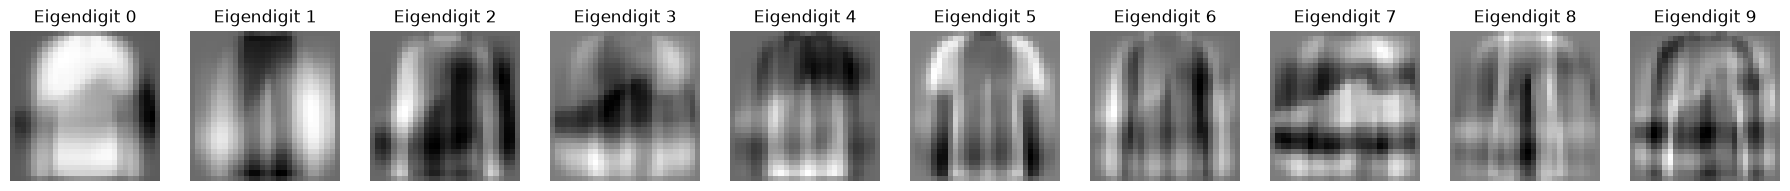

In [20]:
K = 600 
pca = PCA(n_components=K).fit(X_train)
nrows, ncols = 1, 10
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)
for i in range(min(K, nrows * ncols)):
    ax = axs.flat[i]; ax.set_axis_off()
    ax.set_title(f"Eigendigit {i}")
    ax.imshow(pca.components_[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")

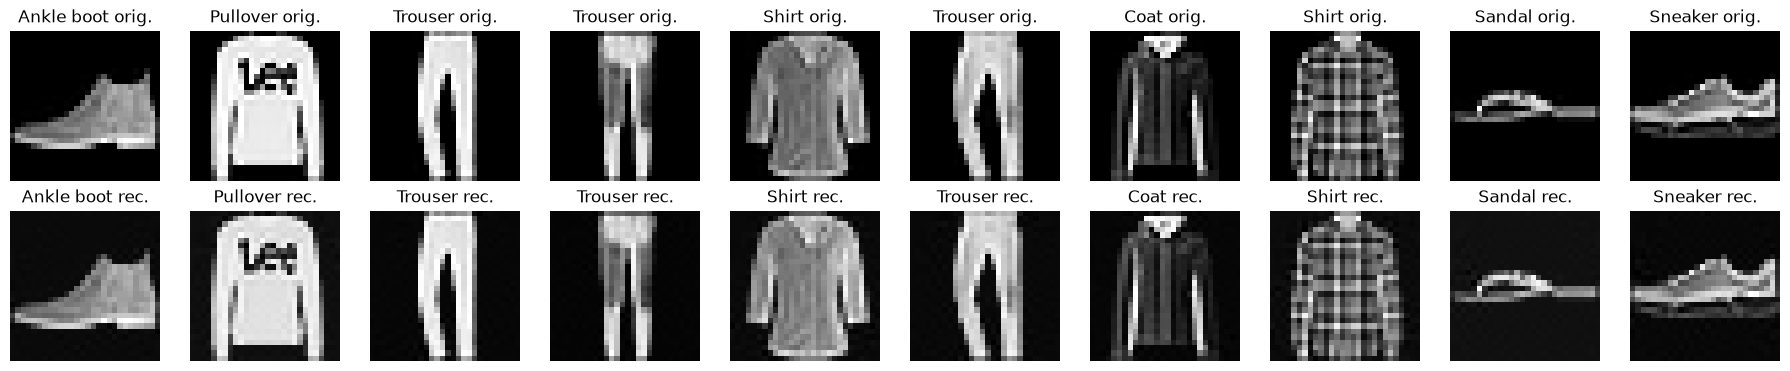

In [21]:
ncols = 10 
Z_test = pca.transform(X_test[:ncols]) 
hX_test = pca.inverse_transform(Z_test)
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)
for i in range(ncols):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"{labels[y_test[i]]} orig.")
    ax.imshow(X_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]; ax.set_axis_off(); ax.set_title(f"{labels[y_test[i]]} rec.")
    ax.imshow(hX_test[i, :].reshape((28, 28)), cmap=plt.cm.gray, interpolation="none")

/Users/vets/Projects/upv/APA/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/vets/Projects/upv/APA/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

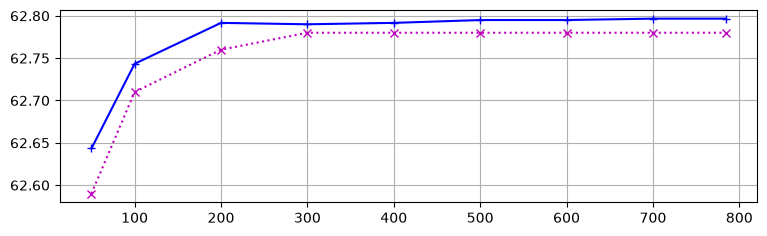

In [25]:
from sklearn.linear_model import LogisticRegression
max_K = np.min(X_train.shape)
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)
Ks = np.array([50, 100, 200, 300, 400, 500, 600, 700, max_K])
acc_train = np.empty_like(Ks, dtype=float); acc_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
    clf = LogisticRegression(C=0.05, max_iter=1).fit(Z_train[:, :K], y_train)
    acc_train[i] = clf.score(Z_train[:, :K], y_train)
    acc_test[i] = clf.score(Z_test[:, :K], y_test)
plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m');

In [ ]:
import numpy as np; import datasets
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy")
X_train = ds['train'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
labels = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

In [ ]:
import matplotlib.pyplot as plt; from sklearn.decomposition import PCA
max_K = np.min(X_train.shape); pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train); Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 500, 1000, 2000, max_K])
L_train = np.empty_like(Ks, dtype=float); L_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
    Z_train_K = Z_train.copy() 
    Z_train_K[:, K:] = 0.0 
    hX_train = pca.inverse_transform(Z_train_K)
    L_train[i] = np.square(X_train - hX_train).sum(axis=1).mean()
    Z_test_K = Z_test.copy(); Z_test_K[:, K:] = 0.0; hX_test = pca.inverse_transform(Z_test_K)
    L_test[i] = np.square(X_test - hX_test).sum(axis=1).mean()
plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m');

In [ ]:
K = 1000; pca = PCA(n_components=K).fit(X_train)
ncols = 10; Z_test = pca.transform(X_test[:ncols]); hX_test = pca.inverse_transform(Z_test)
fig, axs = plt.subplots(nrows=2, ncols=ncols, figsize=(18, 18*2/ncols), constrained_layout=True)
for i in range(ncols):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"{labels[y_test[i]]} orig.")
    ax.imshow(X_test[i, :].reshape((32, 32, 3)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]; ax.set_axis_off(); ax.set_title(f"{labels[y_test[i]]} rec.")
    ax.imshow(hX_test[i, :].reshape((32, 32, 3)), cmap=plt.cm.gray, interpolation="none")

In [ ]:
from sklearn.linear_model import LogisticRegression

max_K = np.min(X_train.shape) 
pca = PCA(n_components=max_K).fit(X_train)
Z_train = pca.transform(X_train) 
Z_test = pca.transform(X_test)
Ks = np.array([100, 200, 500, 1000, 2000, max_K])
acc_train = np.empty_like(Ks, dtype=float); acc_test = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    clf = LogisticRegression(C=0.05, max_iter=200).fit(Z_train[:, :K], y_train)
    acc_train[i] = clf.score(Z_train[:, :K], y_train)
    acc_test[i] = clf.score(Z_test[:, :K], y_test)
plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m');

In [ ]:

for i, K in enumerate(Ks): 
    print(f'{K} {acc_test[i]:.1%}')